# Sprint 4 — PLN: RAG e Assistente de Troubleshooting

**FIAP × Forzy — Grupo CodeX** · Gêmeo Digital para motores elétricos industriais

Guilherme Gama (RM565293) · Bruno Fernandes Nascimento (RM552574) · Edgar Lódula de Assis (RM565260) · Júlia Aben-Athar (RM566325) · Igor Thiago Nakajima Vieira (RM563632)

A Sprint 3 transformou número em texto. Esta sprint fecha o ciclo: um assistente que responde perguntas de troubleshooting **fundamentado na documentação técnica do ativo** (RAG, §2–4) e **sensível ao estado operacional real** do equipamento vindo da Sprint 3 (§5), avaliado por faithfulness, answer relevancy e context precision (§6) e demonstrado em três cenários de falha (§7).


## 1. Ambiente

Roda em CPU. O índice vetorial e as respostas já vêm calculados em `indice_rag/` e `relatorios/`; as células de recomputação são opcionais e estão sinalizadas.


In [1]:
# Colab: descomente na primeira execução
# !pip -q install sentence-transformers faiss-cpu pymupdf transformers torch rouge-score

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "pln").exists() and (RAIZ.parent / "pln").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

DADOS = RAIZ / "dados"
RELATORIOS = RAIZ / "relatorios"
INDICE = RAIZ / "indice_rag"

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 110)
print("raiz:", RAIZ)

raiz: F:\FIAP\Segundo Ano\Challenge Sprints\challenge-sprint-4\processamento-linguagem-natural


## 2. Corpus e chunking

Cinco documentos técnicos WEG em português (as versões em inglês dos mesmos títulos ficam fora do índice para não duplicar chunks): guia de especificação, manual de instalação/operação/manutenção, catálogo W22, artigo de danos em enrolamentos e artigo de rendimento.

**Chunking por seção real, não por tamanho fixo.** Três estratégias em cascata:

1. **Sumário embutido no PDF** — 138 entradas no guia de especificação. Cada título é localizado no corpo do texto (só quando abre uma linha) e a página declarada no sumário desempata ocorrências repetidas. O caminho hierárquico (`7. Características em Regime > 7.1.3 Classes de isolamento`) fica no metadado e entra no texto embutido.
2. **Títulos numerados em caixa alta** — para PDFs sem sumário, caso do manual multilíngue WMO, do qual só as páginas em português são extraídas.
3. **Por página com cabeçalho detectado** — último recurso, usado no catálogo e nos artigos.

Seções longas são divididas em janelas de até 1.100 caracteres com 180 de sobreposição, sempre cortando em fim de frase. Páginas de índice impresso são descartadas: repetem títulos e poluiriam a busca.


In [2]:
chunks = json.loads((INDICE / "chunks.json").read_text(encoding="utf-8"))
resumo = pd.read_csv(RELATORIOS / "chunks_resumo.csv")
display(resumo)
print(f"total: {len(chunks)} chunks | {len({c['secao'] for c in chunks})} seções distintas")
print(f"tamanho médio: {np.mean([c['n_chars'] for c in chunks]):.0f} caracteres")

,doc_id,titulo,tipo,chunks,secoes,paginas,chars_medio
0,catalogo_w22,WEG — Catálogo Técnico W22 Motor Elétrico Monofásico,catalogo,18,2,8,895
1,danos_enrolamento,WEG — Danos em Enrolamentos de Motores Monofásicos,artigo,6,1,1,970
2,guia_especificacao,WEG — Guia de Especificação de Motores Elétricos,guia,273,90,45,923
3,manual_wmo,"WEG — Manual de Instalação, Operação e Manutenção (WMO Safe Area)",manual,27,7,5,966
4,rendimento_monofasicos,WEG — Rendimento nos Motores Monofásicos,artigo,23,1,5,945


total: 347 chunks | 101 seções distintas
tamanho médio: 927 caracteres


In [3]:
# Um chunk carrega o caminho hierárquico da seção, a página e as famílias técnicas
exemplo = next(c for c in chunks if "Classes de isolamento" in c["secao"])
for campo in ("chunk_id", "doc_id", "secao", "pagina", "familias", "n_chars"):
    print(f"{campo:12s}: {exemplo[campo]}")
print("\ntexto:\n", exemplo["texto"][:400], "...")

chunk_id    : CH-0130
doc_id      : guia_especificacao
secao       : 7. Características em Regime > 7.1.3 Classes de isolamento
pagina      : 35
familias    : ['eletrica', 'termica']
n_chars     : 1092

texto:
 so. 
A especificação de alarme e/ou desligamento deve ser 
realizada de acordo com a classe térmica do motor. 
Em caso de dúvidas, consulte a WEG.
7.1.3 Classes de Isolamento
Definição das classes
Como foi visto anteriormente, o limite de temperatura 
depende do tipo de material empregado. Para fins de 
normalização, os materiais isolantes e os sistemas de 
isolamento (cada um formado pela combina ...


In [4]:
# As famílias técnicas viram o filtro contextual do retriever (§4)
from collections import Counter

fam = Counter(f for c in chunks for f in c["familias"])
display(pd.Series(fam).to_frame("chunks"))
print("chunks sem família (conteúdo genérico):", sum(1 for c in chunks if not c["familias"]))

,chunks
manutencao,4
eletrica,173
mecanica,44
termica,57


chunks sem família (conteúdo genérico): 134


## 3. Indexação

Embeddings com `paraphrase-multilingual-MiniLM-L12-v2` — o mesmo modelo escolhido e justificado na Sprint 2, o que mantém a coerência do vocabulário técnico entre a busca no cadastro e a busca na documentação.

O texto embutido em cada vetor é `título do documento — caminho da seção + corpo do chunk`: o cabeçalho técnico entra no embedding, então um trecho sobre tabela de temperaturas continua recuperável pela expressão "classe de isolamento" mesmo quando o corpo não repete o termo.

FAISS `IndexFlatIP` com vetores normalizados (equivale a cosseno). Com algumas centenas de chunks, busca exata é mais simples e mais precisa que índice aproximado.


In [5]:
from pln import rag

indice = rag.IndiceVetorial.carregar(INDICE)
retriever = rag.Retriever(indice)
print(f"índice: {len(indice.chunks)} vetores | modelo: {indice.modelo_nome}")

for chunk, score in indice.buscar("temperatura máxima da classe de isolamento F", k=3):
    print(f"  {score:.3f} | {chunk['doc_id']} p.{chunk['pagina']} | {chunk['secao'][:60]}")

índice: 347 vetores | modelo: paraphrase-multilingual-MiniLM-L12-v2


C:\Users\zecro\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8650.02it/s]

  0.610 | guia_especificacao p.35 | 7. Características em Regime > 7.1.3 Classes de isolamento
  0.603 | guia_especificacao p.44 | 8. Características de ambiente > 8.1 Altitude
  0.580 | guia_especificacao p.50 | 9. Atmosferas explosivas > 9.5 Equipamentos para Áreas de Ri


## 4. Retriever com re-ranking

A busca densa sozinha erra em perguntas com termo técnico exato. O re-ranking soma quatro sinais:

| Sinal | Peso | O que captura |
|-------|------|---------------|
| densidade semântica (FAISS) | 1,00 | proximidade de significado |
| sobreposição lexical | 0,35 | termo técnico literal da pergunta |
| família técnica | 0,25 | **estado do equipamento como filtro**: elétrica, mecânica, térmica ou manutenção |
| termos do ativo | 0,15 | TAG do motor citada no chunk |

O sinal de família é a porta de entrada do contexto operacional: quando o alerta aberto é mecânico, chunks de conteúdo mecânico sobem no ranking.

**Avaliação** contra o gabarito de 20 perguntas (`dados/perguntas_troubleshooting.json`), em que cada pergunta declara documento e seção que sustentam a resposta.


In [6]:
metricas_ret = json.loads((RELATORIOS / "metricas_retriever.json").read_text(encoding="utf-8"))
display(pd.DataFrame(metricas_ret["por_configuracao"]))
display(pd.DataFrame(metricas_ret["por_k"])[["k", "context_precision", "context_recall", "hit_rate", "mrr"]])

,configuracao,context_precision,context_recall,hit_rate,mrr
0,denso_puro,0.2500,0.8,0.8,0.5625
1,denso_lexical,0.3375,0.9,0.9,0.7583
2,denso_lexical_contexto,0.3125,0.9,0.9,0.6958


,k,context_precision,context_recall,hit_rate,mrr
0,1,0.6500,0.65,0.65,0.6500
1,3,0.4000,0.90,0.90,0.7583
2,4,0.3375,0.90,0.90,0.7583
3,6,0.2500,0.90,0.90,0.7583
4,10,0.1650,0.90,0.90,0.7583


In [7]:
detalhe = pd.DataFrame(metricas_ret["detalhe_denso_lexical"])
print("perguntas em que nenhuma fonte correta apareceu no top-4:")
display(detalhe[detalhe.hit == 0][["id", "categoria", "top1_doc", "top1_secao"]])
display(detalhe.groupby("categoria")[["precision", "recall", "rr"]].mean().round(3))

perguntas em que nenhuma fonte correta apareceu no top-4:


,id,categoria,top1_doc,top1_secao
15,T16,anomalia_mecanica,rendimento_monofasicos,WEG em Revista
18,T19,manutencao_preventiva,manual_wmo,"2 TRANSPORTE, ARMAZENAMENTO E MANUSEIO"


,precision,recall,rr
categoria,,,
anomalia_eletrica,0.417,1.0,0.917
anomalia_mecanica,0.125,0.5,0.500
especificacao,0.393,1.0,0.738
manutencao_preventiva,0.250,0.8,0.700


> **Teto da precisão.** A maioria das perguntas tem uma única seção de gabarito, e uma seção rende poucos chunks. Com k=4, uma recuperação perfeita frequentemente atinge precisão de 0,25 a 0,50 — o sinal que interessa aqui é o **recall** (a fonte certa apareceu?) e o **MRR** (em que posição).


## 5. Assistente conversacional

LLM local: **Qwen2.5-3B-Instruct** quantizado (GGUF Q4_K_M via `llama-cpp-python`) em CPU, geração determinística (temperatura 0). Roda sem GPU; a variável de ambiente `MODELO_LLM` aceita outro repositório GGUF, um caminho local `.gguf` ou um modelo `transformers`.

O prompt de sistema fixa quatro obrigações: responder só pelas FONTES, marcar cada frase com `[FONTE n]`, declarar quando a documentação não cobre a pergunta e fechar com um nível de confiança justificado.

**Desde a Sprint 4, duas decisões saem do LLM e passam para o código** (§8): se a relevância do melhor trecho recuperado for menor que 0,60, a pergunta é recusada sem chamar o modelo; e a confiança exibida ao operador é a calculada pela recuperação — a que o modelo declara fica só no registro, para comparação.

Três camadas de contexto entram no prompt:
1. trechos recuperados pelo RAG;
2. **estado operacional do ativo** — situação e resumos de alerta gerados na Sprint 3;
3. histórico recente do diálogo (memória de curto prazo, 3 turnos).


In [8]:
from pln.assistente import PROMPT_SISTEMA, TEMPLATE_USUARIO, bloco_estado

print(PROMPT_SISTEMA)
print("\n" + "=" * 70 + "\nMENSAGEM DO USUÁRIO (estrutura):\n")
print(TEMPLATE_USUARIO.format(estado="{bloco de estado do ativo}\n\n",
                              contexto="{trechos recuperados}", pergunta="{pergunta}"))

Você é um assistente técnico especialista em motores elétricos industriais, apoiando operadores de manutenção de uma planta industrial.

Regras obrigatórias:
1. Responda SOMENTE com base nos trechos fornecidos em FONTES e no ESTADO DO ATIVO. Não use conhecimento externo e não invente números, normas ou procedimentos.
2. TODA frase apoiada em um trecho deve terminar com a marca da fonte, no formato [FONTE 1], [FONTE 2], etc. Frases sem marca de fonte serão consideradas sem embasamento.
3. Se as FONTES não cobrirem a pergunta, diga explicitamente que a documentação disponível não trata do assunto e não tente adivinhar.
4. Números, faixas e nomes de normas devem ser copiados literalmente das FONTES. Nunca cite uma norma, tabela ou valor que não apareça no texto fornecido.
5. Escreva em português técnico acessível, direto, em no máximo 6 frases.
6. Termine com uma linha no formato: Confiança: ALTA|MÉDIA|BAIXA — seguida de uma justificativa curta baseada na aderência dos trechos recuperados

In [9]:
# Contexto operacional vindo da Sprint 3 (mesmos artefatos, sem recalcular)
import importlib.util

spec = importlib.util.spec_from_file_location("aval_ass", RAIZ / "scripts" / "avaliar_assistente.py")
aval_ass = importlib.util.module_from_spec(spec)
sys.modules["aval_ass"] = aval_ass
spec.loader.exec_module(aval_ass)

estados = aval_ass.contexto_operacional()
print(bloco_estado(estados["MT-008"]))

ESTADO DO ATIVO MT-008 (W22-112M-4P-7.5CV-3F):
- Situação: EM RISCO — alertas críticos abertos
- ALERTA CRÍTICO — motor W22-112M-4P-7.5CV-3F (Linha de Produção B — Misturador Industrial). A temperatura do mancal atingiu desvio severo de +17,8 C sobre o baseline de 49,8 C de forma sustentada por 5,1 dias, com valor de pico em 67,1 C. Risco de falha do rolamento por perda de lubrificação. Intervenção imediata requerida: parada para inspeção do mancal e substituição do rolamento — acionar manutenção no turno corrente.
- ALERTA CRÍTICO: W22-112M-4P-7.5CV-3F em condição severa. Leitura de vibração global registrada em 4,4 mm/s (+112,8% vs. baseline) de forma sustentada por 5 dias. Intervenção imediata requerida — parada para verificação de alinhamento, balanceamento e rolamentos. Manter o ativo sob supervisão contínua até a intervenção.




### 5.1 Executar o assistente ao vivo (opcional)

Com o Qwen2.5-3B quantizado (GGUF Q4_K_M, `llama-cpp-python`) cada resposta leva cerca de 20 s em CPU. As respostas do conjunto de avaliação já estão em `relatorios/respostas_assistente.csv`; mude `RODAR_AO_VIVO = True` para gerar uma nova. Para usar um `.gguf` já baixado, defina a variável de ambiente `MODELO_LLM` com o caminho do arquivo.


In [10]:
RODAR_AO_VIVO = False

if RODAR_AO_VIVO:
    from pln.assistente import Assistente

    assistente = Assistente(retriever)
    r = assistente.responder(
        "A vibração deste motor mais que dobrou em cinco dias. O que verificar primeiro?",
        estado=estados["MT-008"], familias=["mecanica"])
    print(r["resposta"])
    print("\nfontes citadas:", r["fontes_citadas"],
          "| confiança calculada:", r["confianca_recuperacao"],
          "| confiança que o modelo declarou:", r["confianca_declarada"],
          "| números sem fonte literal:", r["numeros_sem_suporte"] or "nenhum")
else:
    print("execução ao vivo desativada — ver §6 e §7 para as respostas geradas")

execução ao vivo desativada — ver §6 e §7 para as respostas geradas


## 6. Avaliação da geração

| Métrica | Como é medida (tudo offline) |
|---------|------------------------------|
| **faithfulness** | cada frase da resposta é testada por entailment contra os trechos recuperados, com o modelo NLI multilíngue mDeBERTa — o mesmo já usado na Sprint 3. A métrica é a fração de frases sustentadas |
| **answer relevancy** | similaridade de cosseno entre os embeddings da pergunta e da resposta |
| **cobertura da referência** | ROUGE-1/L contra a resposta de referência escrita à mão a partir dos manuais |
| **citação e confiança** | percentual de respostas que marcam a fonte e que declaram nível de confiança |


In [11]:
CAMINHO_RESP = RELATORIOS / "respostas_assistente.csv"
CAMINHO_MET = RELATORIOS / "metricas_assistente.json"
TEM_RESULTADOS = CAMINHO_RESP.exists() and CAMINHO_MET.exists()

if not TEM_RESULTADOS:
    print("execute `python scripts/avaliar_assistente.py` para gerar as respostas")
respostas = pd.read_csv(CAMINHO_RESP) if TEM_RESULTADOS else pd.DataFrame()
metricas = json.loads(CAMINHO_MET.read_text(encoding="utf-8")) if TEM_RESULTADOS else {}

if TEM_RESULTADOS:
    display(pd.Series({k: v for k, v in metricas.items()
                       if isinstance(v, (int, float, str))}).to_frame("valor"))
    display(pd.DataFrame(metricas["por_categoria"]))

,valor
modelo_llm,F:/hf-cache/hub/models--Qwen--Qwen2.5-3B-Instruct-GGUF/snapshots/7dabda4d13d513e3e842b20f0d435c732f172cbe/...
n_perguntas,20
faithfulness_medio,0.6775
answer_relevancy_medio,0.7338
rouge1_f_medio,0.3783
rougeL_f_medio,0.2912
respostas_com_citacao_pct,95.0
confianca_declarada_pct,100.0
tempo_medio_s,19.9
fora_de_escopo_recusa_pct,100.0


,faithfulness,answer_relevancy,rouge1_f
anomalia_eletrica,0.8333,0.6491,0.3856
anomalia_mecanica,1.0000,0.7004,0.2769
especificacao,0.4571,0.7916,0.4130
manutencao_preventiva,0.6700,0.7677,0.3615


In [12]:
# Uma resposta boa e uma ruim, lado a lado com a referência
if not TEM_RESULTADOS:
    raise SystemExit
melhor = respostas.sort_values("faithfulness", ascending=False).iloc[0]
pior = respostas.sort_values("faithfulness").iloc[0]
for rotulo, linha in (("MAIOR FAITHFULNESS", melhor), ("MENOR FAITHFULNESS", pior)):
    print("=" * 25, rotulo, f"({linha['id']}, faithfulness={linha['faithfulness']})")
    print("PERGUNTA :", linha["pergunta"])
    print("GERADA   :", linha["resposta"][:600])
    print("REFERÊNCIA:", linha["resposta_referencia"][:400])
    print()

========================= MAIOR FAITHFULNESS (T09, faithfulness=1.0)
PERGUNTA : Como é expressa a corrente de rotor bloqueado nas normas?
GERADA   : A corrente de rotor bloqueado é expressa nas normas como Ip, onde Ip = Corrente com rotor bloqueado. [FONTE 1]
Confiança: MÉDIA — calculada pela recuperação (relevância do melhor trecho: 0,82).
REFERÊNCIA: Os limites máximos de corrente com rotor bloqueado são expressos em termos da potência aparente absorvida com rotor bloqueado em relação à potência nominal, na razão kVA/cv ou kVA/kW (Sp/Pn), calculada a partir da corrente de partida e da tensão nominal. Os limites valem para qualquer número de polos, variando conforme a faixa de potência.

========================= MENOR FAITHFULNESS (T01, faithfulness=0.0)
PERGUNTA : Qual a temperatura máxima do ponto mais quente para a classe de isolamento F e como ela se compõe?
GERADA   : [FONTE 1] Para a classe de isolamento F, a temperatura máxima do ponto mais quente é de 150 °C [FONTE 1]. [FONTE

In [13]:
# Frases que o juiz NLI não conseguiu sustentar nos trechos recuperados
sem_suporte = metricas.get("sentencas_sem_suporte", {})
print(f"{len(sem_suporte)} respostas com ao menos uma frase sem suporte\n")
for pid, frases in list(sem_suporte.items())[:6]:
    print(f"[{pid}]")
    for f in frases[:2]:
        print("   -", f[:180])
    print()

10 respostas com ao menos uma frase sem suporte

[T01]
   - Para a classe de isolamento F, a temperatura máxima do ponto mais quente é de 150 °C  .

[T02]
   - A elevação de temperatura é a soma da queda interna e da queda externa, como indicado na figura  .
   - A queda interna pode ser medida no interior do motor, na ranhura onde ocorre o calor proveniente das perdas nos condutores  .

[T03]
   - No entanto, a capacidade de dissipação da potência do motor pode ser reduzida, conforme indicado na tabela 8.3 de  .
   - Portanto, a instalação a 1.500 metros pode reduzir a capacidade de dissipação da potência do motor, mas não afeta sua capacidade para sobrecargas momentâneas.

[T04]
   - b) Formação de gelo nos mancais, provocando endurecimento das graxas ou lubrificantes nos mancais, exigindo o emprego de lubrificantes especiais ou graxa anticongelante (consulte n

[T05]
   - Para calcular a potência útil do motor, primeiro determinamos a redução necessária na temperatura ambiente, que 

### 6.1 Perguntas fora do escopo

Quatro perguntas sem cobertura documental — preço, equipamento de terceiro, previsão do tempo e vida útil restante — verificam se o assistente recusa em vez de inventar.


In [14]:
fora = (pd.read_csv(RELATORIOS / "fora_de_escopo.csv")
        if (RELATORIOS / "fora_de_escopo.csv").exists() else pd.DataFrame(columns=["id", "pergunta", "resposta", "recusou"]))
print(f"recusa explícita em {fora['recusou'].sum()} de {len(fora)} perguntas\n")
for _, linha in fora.iterrows():
    print(f"[{linha['id']}] {linha['pergunta']}")
    print("   ", linha["resposta"][:260].replace("\n", " "), "\n")

recusa explícita em 4 de 4 perguntas

[F01] Qual o preço de um motor W22 de 15 cv e o prazo de entrega?
    Não há informações sobre o preço ou prazo de entrega dos motores W22 em nenhuma das fontes fornecidas. Confiança: MÉDIA — calculada pela recuperação (relevância do melhor trecho: 0,65). 

[F02] Como configuro o inversor de frequência da marca concorrente modelo XYZ-500?
    A documentação técnica disponível não trata deste assunto com aderência suficiente para uma resposta segura. Consulte a engenharia de manutenção ou o canal responsável pela informação. Confiança: BAIXA — calculada pela recuperação (relevância do melhor trecho: 

[F03] Qual a previsão de chuva para a planta amanhã?
    A documentação técnica disponível não trata deste assunto com aderência suficiente para uma resposta segura. Consulte a engenharia de manutenção ou o canal responsável pela informação. Confiança: BAIXA — calculada pela recuperação (relevância do melhor trecho: 

[F04] Qual é a vida útil restante,

## 7. Três cenários de falha

Cada cenário injeta o estado real do ativo (Sprint 3) no prompt e tem dois turnos, para exercitar a memória de curto prazo.


In [15]:
caminho_cen = RELATORIOS / "cenarios_demo.json"
cenarios = json.loads(caminho_cen.read_text(encoding="utf-8")) if caminho_cen.exists() else []

for c in cenarios:
    print("=" * 78)
    print(f"CENÁRIO: {c['cenario'].replace('_', ' ').upper()} — ativo {c['ativo_id']}")
    if c.get("estado"):
        print(f"Estado: {c['estado']['situacao']}")
        for a in c["estado"]["alertas"][:2]:
            print("  •", a[:150])
    for i, turno in enumerate(c["dialogo"], start=1):
        print(f"\n--- turno {i}")
        print("OPERADOR :", turno["pergunta"])
        print("ASSISTENTE:", turno["resposta"][:700])
        fontes = ", ".join(f"{ch['doc_id']} p.{ch['pagina']}" for ch in turno["chunks"][:3])
        print("trechos  :", fontes)
    print()

CENÁRIO: ANOMALIA ELETRICA — ativo MT-007
Estado: EM OBSERVAÇÃO — desvio moderado em acompanhamento
  • Alerta moderado detectado no motor WMagnet-IPM-50CV-3F (Linha de Produção A — Extrusora Principal). O fator de potência apresentou desvio de -0,08 aba
  • Alerta moderado detectado: WMagnet-IPM-50CV-3F opera com temperatura do enrolamento em 75,1 C, desvio +13,7 C sobre a referência de 61,5 C nas últimas

--- turno 1
OPERADOR : O fator de potência deste motor caiu de 0,95 para 0,88. O que pode explicar isso?
ASSISTENTE: [FONTE 1] O fator de potência (pf) é uma medida da eficiência do motor, indicando a proporção da potência real que o motor usa em relação à potência nominal. [FONTE 2] Um desvio moderado no fator de potência pode indicar sobrecarga ou problemas de carga. [FONTE 3] O alerta moderado detectado sugere que o motor opera com carga acima do regime. [FONTE 4] A temperatura do enrolamento em 75,1°C, além do desvio de -0,08, pode indicar sobrecarga ou problemas de refrigeração

## 8. Evolução final (Sprint 4): antes × depois

Quatro ajustes no assistente, todos motivados por falhas registradas na avaliação anterior:

| Ajuste | Falha que motivou |
|--------|-------------------|
| **Recusa determinística por limiar de relevância** (0,60, sem os bônus de contexto) — o LLM nem é chamado | F02: o modelo "configurou" o inversor de um concorrente citando documentos da WEG |
| **Confiança exibida = confiança calculada pela recuperação**; a do modelo fica só no registro | o modelo declarou ALTA em todas as 20 perguntas, inclusive nas duas com recuperação errada |
| **Exemplo do prompt trocado por marcadores sem conteúdo** (`<causa tirada de um trecho> [FONTE 1]`) | a resposta de T16 saiu copiada do exemplo do prompt; a 1ª troca, por um exemplo de compressor, vazou para T18 ("filtro a cada 2 000 horas") e foi pega pelo verificador de números |
| **Verificador de números sem fonte literal** | T01: 155 °C virou 150 °C |

O baseline é reavaliado com a mesma régua (métricas sobre o corpo da resposta, sem a linha de confiança) por `scripts/comparar_sprint3.py`. A primeira iteração da Sprint 4 (com o exemplo do compressor) fica preservada em `relatorios/sprint4_iteracao1/`.


In [16]:
caminho_cmp = RELATORIOS / "comparativo_sprint3_sprint4.json"
if caminho_cmp.exists():
    cmp = json.loads(caminho_cmp.read_text(encoding="utf-8"))
    tabela = pd.DataFrame({"Sprint 3": cmp["sprint3"], "Sprint 4": cmp["sprint4"]})
    display(tabela.astype(str))
    print("Sprint 3 como publicado (com a linha de confiança no juiz):",
          cmp["sprint3_publicado_original"])
else:
    print("execute `python scripts/comparar_sprint3.py`")

,Sprint 3,Sprint 4
faithfulness_medio,0.7433,0.6775
answer_relevancy_medio,0.7248,0.7338
respostas_com_citacao_pct,100.0,95.0
fora_de_escopo_recusadas,3 de 4,4 de 4
fora_de_escopo_nao_recusadas,['F02'],[]
confianca_exibida,{'ALTA': 20},"{'MÉDIA': 12, 'ALTA': 7, 'BAIXA': 1}"
confianca_do_modelo,{'ALTA': 20},"{'ALTA': 18, 'NAO_GERADA': 1, 'MÉDIA': 1}"
respostas_com_numero_sem_suporte,"['T01', 'T05']","['T01', 'T05']"
tempo_medio_s,20.3,19.9


Sprint 3 como publicado (com a linha de confiança no juiz): {'faithfulness_medio': 0.69, 'answer_relevancy_medio': 0.7358, 'observacao': 'calculado com a linha de confiança dentro da resposta'}


In [17]:
# A confiança calculada discrimina? Faithfulness média por nível exibido
if TEM_RESULTADOS:
    display(respostas.groupby("confianca_recuperacao")
            .agg(n=("id", "count"), faithfulness=("faithfulness", "mean"),
                 relevancia_max=("relevancia_max", "mean")).round(3))
    print("recusas por limiar no gabarito (falsos negativos):",
          respostas.loc[respostas["recusa_por_limiar"] == 1, "id"].tolist())
    print("respostas com número sem fonte literal:",
          respostas.loc[respostas["numeros_sem_suporte"].fillna("") != "",
                        ["id", "numeros_sem_suporte"]].values.tolist())

,n,faithfulness,relevancia_max
confianca_recuperacao,,,
ALTA,7,0.564,0.977
BAIXA,1,1.000,0.545
MÉDIA,12,0.717,0.785


recusas por limiar no gabarito (falsos negativos): ['T13']
respostas com número sem fonte literal: [['T01', '150'], ['T05', '32;1800']]


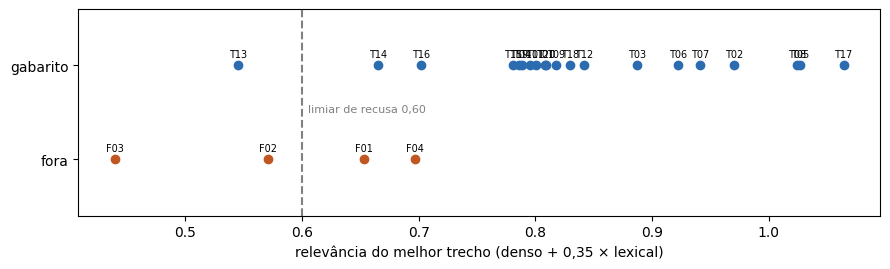

In [18]:
# Relevância de recuperação: gabarito x fora de escopo (por que 0,60)
import matplotlib.pyplot as plt

if caminho_cmp.exists():
    rel = cmp["relevancia_recuperacao"]
    fig, ax = plt.subplots(figsize=(9, 2.8))
    ax.scatter(list(rel["gabarito_por_id"].values()), [1] * len(rel["gabarito_por_id"]),
               label="gabarito (20)", color="#2b6cb0")
    ax.scatter(list(rel["fora_de_escopo_por_id"].values()), [0] * len(rel["fora_de_escopo_por_id"]),
               label="fora de escopo (4)", color="#c05621")
    for pid, v in {**rel["gabarito_por_id"], **rel["fora_de_escopo_por_id"]}.items():
        ax.annotate(pid, (v, 1 if pid.startswith("T") else 0), fontsize=7,
                    xytext=(0, 6), textcoords="offset points", ha="center")
    ax.axvline(0.60, ls="--", color="gray")
    ax.text(0.605, 0.5, "limiar de recusa 0,60", fontsize=8, color="gray")
    ax.set_yticks([0, 1], ["fora", "gabarito"])
    ax.set_xlabel("relevância do melhor trecho (denso + 0,35 × lexical)")
    ax.set_ylim(-0.6, 1.6)
    plt.tight_layout()
    plt.show()

## 9. Limites e mitigação

**O limiar foi escolhido olhando as mesmas 24 perguntas em que é avaliado.** As distribuições se sobrepõem (T13 fica abaixo de F02), então nenhum valor separa os dois grupos sem erro; 0,60 troca uma recusa indevida (T13) por uma alucinação evitada (F02). Com tão poucas perguntas, o número deve ser revalidado num conjunto novo antes de ir para produção.

**O tamanho do LLM importa, e foi medido.** A primeira versão usava Qwen2.5-1.5B: ele ignorava a marca `[FONTE n]` na maioria das respostas e chegou a trocar um valor de tabela (155 °C viraram 125 °C) e a citar uma norma inexistente. A troca para o 3B corrigiu a maior parte disso — mas o modelo continua pequeno para o padrão de assistentes RAG. Com a quantização Q4 o custo caiu para ~20 s por resposta em CPU. Mitigações adotadas: regra de cópia literal de números e normas, exigência da marca de fonte repetida ao final da mensagem do usuário, corte automático da geração depois da linha de confiança e medição de faithfulness frase a frase, que expõe as afirmações sem suporte em vez de escondê-las.

**Faithfulness é medida por NLI, não por juiz LLM.** Um modelo NLI de 279M parâmetros julga entailment frase a frase; é reprodutível e offline, mas mais rígido que um juiz LLM com paráfrases longas — tende a subestimar respostas corretas escritas com vocabulário diferente do trecho.

**O corpus limita o alcance.** Cinco documentos, majoritariamente de especificação. Procedimentos de manutenção detalhados (intervalos de relubrificação por carcaça, torques de aperto) não estão no material em português indexado, então perguntas desse tipo caem em recuperação fraca — comportamento visível nas falhas de recall da §4.

**O filtro por família ajuda no cenário, não na média.** Nas perguntas gerais do gabarito o reforço por família não melhora a precisão (§4); ele existe para o caso de uso real, em que a pergunta chega junto com um alerta aberto de família conhecida.

**Fronteira de escopo depende de frase-gatilho.** A detecção de recusa procura expressões como "não trata" ou "não consta"; uma recusa redigida de outra forma seria contada como falha. É uma medição conservadora, não um limite do assistente.
